# Superstore Sales & Profitability Analysis

**Author:** Daljeet Kaur
**Tools:** Python (pandas, matplotlib) for cleaning and analysis · **Excel** (SUMIFS/COUNTIFS/AVERAGEIFS, INDEX/MATCH, data validation, conditional formatting, charts) for the stakeholder workbook
**Dataset:** Tableau's "Sample – Superstore" (US office-supplies, furniture and technology retailer, 2015–2018), raw export

## Business problem
Superstore's sales are growing, but leadership feels profit isn't keeping up. They want to know **where the company makes and loses money** and whether **discounting** is to blame. Regional managers also want a workbook they can open in Excel and filter themselves.

## Objectives
1. Clean the raw export into analysis-ready tables.
2. Track sales, profit and margin by year.
3. Find the categories, products and states that lose money.
4. Quantify how discount levels affect profit.
5. Measure return rates by region.
6. Deliver an interactive **Excel workbook** for regional managers (built by `scripts/build_excel_workbook.py`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 25)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE, GREY, RED, GREEN = "#2563eb", "#9ca3af", "#dc2626", "#16a34a"
IMG_DIR, RESULTS_DIR = "../images", "../results"
usd = mtick.FuncFormatter(lambda v, _: f"${v/1e3:,.0f}K")

## 1. Load the raw export

In [2]:
raw = pd.read_csv("../data/superstore_raw.csv", encoding="latin1")
print(raw.shape)
raw.tail(3)

(10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10797,Yes,US-2018-151127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10798,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10799,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
print("Rows with no Order Date:", raw["Order Date"].isna().sum())
raw[raw["Order Date"].isna()].head(8)[["Row ID", "Order ID"]]

Rows with no Order Date: 806


,Row ID,Order ID
9994,Person,Region
9995,Anna Andreadi,West
9996,Chuck Magee,East
9997,Kelly Williams,Central
9998,Cassandra Brandow,South
9999,Returned,Order ID
10000,Yes,CA-2015-100762
10001,Yes,CA-2015-100762


**Data issue found:** the export has **three tables stacked into one file**. After the 9,994 order lines comes a `Person / Region` table (regional managers) and then a `Returned / Order ID` table, pushed into the first two columns. They need to be split apart, not just dropped. The Returns table is useful in its own right.

## 2. Clean and split

In [4]:
blank = raw["Order Date"].isna()
orders = raw[~blank].copy()
tail = raw.loc[blank, ["Row ID", "Order ID"]].reset_index(drop=True)
split = tail.index[tail["Row ID"] == "Returned"][0]

people = tail.iloc[1:split].rename(columns={"Row ID": "Manager", "Order ID": "Region"})
returns_raw = tail.iloc[split + 1:].rename(columns={"Row ID": "Returned", "Order ID": "Order ID"})
returns = returns_raw.drop_duplicates()

orders["Row ID"] = orders["Row ID"].astype(int)
for c in ["Order Date", "Ship Date"]:
    orders[c] = pd.to_datetime(orders[c], format="%m/%d/%Y")
orders["Postal Code"] = orders["Postal Code"].fillna(5401).astype(int)   # Burlington, VT: 05401
orders["Quantity"] = orders["Quantity"].astype(int)
orders["Year"] = orders["Order Date"].dt.year
orders["Ship Days"] = (orders["Ship Date"] - orders["Order Date"]).dt.days
orders["Returned"] = orders["Order ID"].isin(returns["Order ID"]).map({True: "Yes", False: "No"})
orders = orders.merge(people, on="Region", how="left")

checks = pd.Series({
    "order lines": len(orders),
    "duplicate order lines": int(orders.duplicated().sum()),
    "unique orders": orders["Order ID"].nunique(),
    "regional managers": len(people),
    "return rows (raw)": len(returns_raw),
    "returned orders (deduplicated)": len(returns),
    "returned orders found in Orders": int(returns["Order ID"].isin(orders["Order ID"]).sum()),
    "missing postal codes fixed": 11,
    "ship date before order date": int((orders["Ship Days"] < 0).sum()),
})
checks

order lines                        9994
duplicate order lines                 0
unique orders                      5009
regional managers                     4
return rows (raw)                   800
returned orders (deduplicated)      296
returned orders found in Orders     296
missing postal codes fixed           11
ship date before order date           0
dtype: int64

In [5]:
orders.to_csv("../data/clean/orders_clean.csv", index=False)
people.to_csv("../data/clean/regional_managers.csv", index=False)
returns.to_csv("../data/clean/returned_orders.csv", index=False)
print(f"Sales ${orders.Sales.sum():,.0f}  |  Profit ${orders.Profit.sum():,.0f}  |  "
      f"Margin {orders.Profit.sum() / orders.Sales.sum():.1%}  |  {orders['Order Date'].min().date()} to {orders['Order Date'].max().date()}")

Sales $2,297,201  |  Profit $286,397  |  Margin 12.5%  |  2015-01-03 to 2018-12-30


Cleaning summary: 10,800 raw rows → **9,994 order lines** with no duplicates, plus a 4-row manager table and **296 returned orders** (504 duplicate rows removed). The 11 missing postal codes were all Burlington, VT, and were filled with its ZIP code (05401).

## 3. Growth: sales vs profit by year

In [6]:
yearly = orders.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
yearly["Margin"] = yearly.Profit / yearly.Sales
yearly["Sales YoY"] = yearly.Sales.pct_change()
yearly["Profit YoY"] = yearly.Profit.pct_change()
yearly.round(3)

,Sales,Profit,Orders,Margin,Sales YoY,Profit YoY
Year,,,,,,
2015,484247.498,49543.974,969,0.102,NaN,NaN
2016,470532.509,61618.604,1038,0.131,-0.028,0.244
2017,609205.598,81795.174,1315,0.134,0.295,0.327
2018,733215.255,93439.270,1687,0.127,0.204,0.142


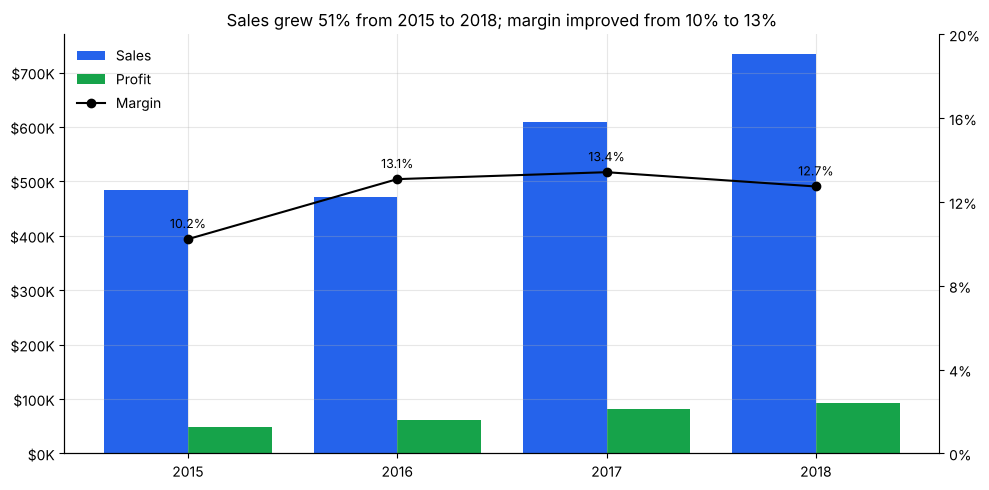

In [7]:
fig, ax1 = plt.subplots()
x = np.arange(len(yearly))
ax1.bar(x - 0.2, yearly.Sales, 0.4, color=BLUE, label="Sales")
ax1.bar(x + 0.2, yearly.Profit, 0.4, color=GREEN, label="Profit")
ax1.set_xticks(x, yearly.index)
ax1.yaxis.set_major_formatter(usd)
ax2 = ax1.twinx()
ax2.plot(x, yearly.Margin, color="black", marker="o", label="Margin")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax2.set_ylim(0, 0.2); ax2.yaxis.set_major_locator(mtick.MultipleLocator(0.04)); ax2.grid(False); ax2.spines["right"].set_visible(True)
for i, m in enumerate(yearly.Margin):
    ax2.annotate(f"{m:.1%}", (i, m), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, frameon=False, loc="upper left")
ax1.set_title("Sales grew 51% from 2015 to 2018; margin improved from 10% to 13%")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/01_sales_profit_by_year.png", dpi=150)

## 4. Where does the company lose money?

In [8]:
subcat = (orders.groupby(["Category", "Sub-Category"])
          .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Avg_Discount=("Discount", "mean"))
          .reset_index())
subcat["Margin"] = subcat.Profit / subcat.Sales
subcat = subcat.sort_values("Profit")
subcat.round(3)

,Category,Sub-Category,Sales,Profit,Avg_Discount,Margin
3,Furniture,Tables,206965.532,-17725.481,0.261,-0.086
0,Furniture,Bookcases,114879.996,-3472.556,0.211,-0.030
12,Office Supplies,Supplies,46673.538,-1189.100,0.077,-0.025
8,Office Supplies,Fasteners,3024.280,949.518,0.082,0.314
15,Technology,Machines,189238.631,3384.757,0.306,0.018
9,Office Supplies,Labels,12486.312,5546.254,0.069,0.444
5,Office Supplies,Art,27118.792,6527.787,0.075,0.241
7,Office Supplies,Envelopes,16476.402,6964.177,0.080,0.423
2,Furniture,Furnishings,91705.164,13059.144,0.138,0.142
4,Office Supplies,Appliances,107532.161,18138.005,0.167,0.169


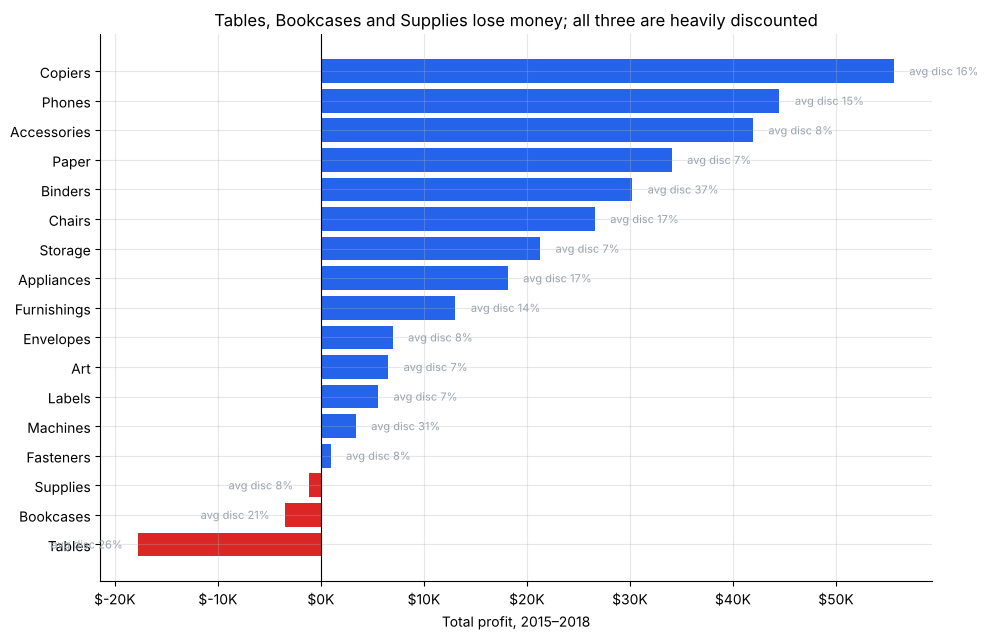

In [9]:
fig, ax = plt.subplots(figsize=(10, 6.5))
colors = [RED if p < 0 else BLUE for p in subcat.Profit]
ax.barh(subcat["Sub-Category"], subcat.Profit, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.xaxis.set_major_formatter(usd)
for i, (p, d) in enumerate(zip(subcat.Profit, subcat.Avg_Discount)):
    ax.text(p + (1500 if p >= 0 else -1500), i, f"avg disc {d:.0%}", va="center",
            ha="left" if p >= 0 else "right", fontsize=8, color=GREY)
ax.set_xlabel("Total profit, 2015–2018")
ax.set_title("Tables, Bookcases and Supplies lose money; all three are heavily discounted")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/02_profit_by_subcategory.png", dpi=150)

**Finding:** Three sub-categories lose money over four years: **Tables (−$17.7K)**, **Bookcases (−$3.5K)** and **Supplies (−$1.2K)**. Tables and Bookcases carry average discounts of 26% and 21%. Copiers, Phones and Accessories carry the business.

## 5. Is discounting to blame?

In [10]:
bands = pd.cut(orders.Discount, [-0.01, 0, 0.1, 0.2, 0.3, 0.5, 0.9],
               labels=["0%", "1–10%", "11–20%", "21–30%", "31–50%", "51–80%"])
disc = orders.groupby(bands, observed=True).agg(Lines=("Sales", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"))
disc["Margin"] = disc.Profit / disc.Sales
disc["Share of lines"] = disc.Lines / disc.Lines.sum()
disc.round(3)

,Lines,Sales,Profit,Margin,Share of lines
Discount,,,,,
0%,4798,1087908.470,320987.603,0.295,0.480
1–10%,94,54369.351,9029.177,0.166,0.009
11–20%,3709,792152.890,91756.298,0.116,0.371
21–30%,227,103226.655,-10369.277,-0.100,0.023
31–50%,310,195314.757,-48447.727,-0.248,0.031
51–80%,856,64228.738,-76559.051,-1.192,0.086


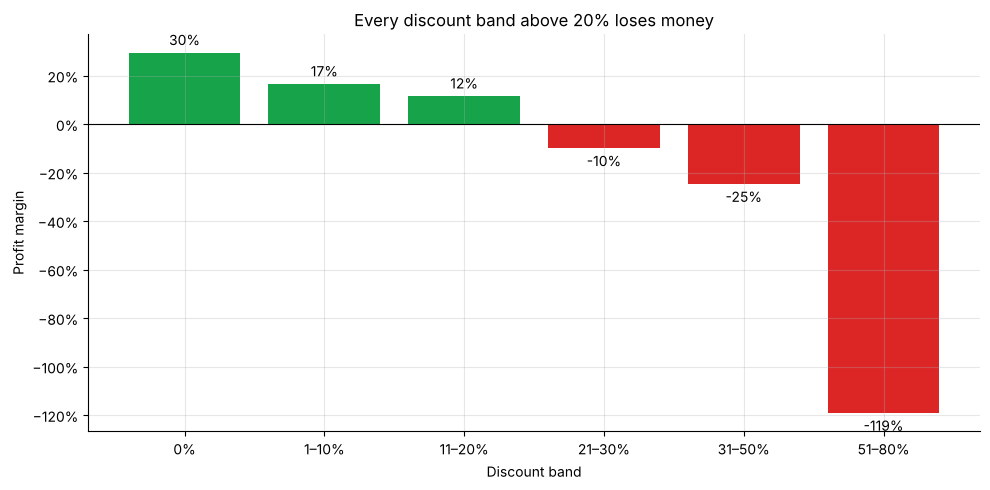

In [11]:
fig, ax = plt.subplots()
bars = ax.bar(disc.index.astype(str), disc.Margin, color=[GREEN if m > 0 else RED for m in disc.Margin])
ax.bar_label(bars, labels=[f"{m:.0%}" for m in disc.Margin], padding=3)
ax.axhline(0, color="black", lw=0.8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("Discount band"); ax.set_ylabel("Profit margin")
ax.set_title("Every discount band above 20% loses money")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/03_margin_by_discount.png", dpi=150)

In [12]:
deep = orders[orders.Discount > 0.2]
print(f"Lines discounted >20%: {len(deep):,} ({len(deep) / len(orders):.0%} of lines), "
      f"sales ${deep.Sales.sum():,.0f}, profit ${deep.Profit.sum():,.0f}")
print(f"Profit on all other lines: ${orders.loc[orders.Discount <= 0.2, 'Profit'].sum():,.0f}")

Lines discounted >20%: 1,393 (14% of lines), sales $362,770, profit $-135,376
Profit on all other lines: $421,773


**Finding:** Discounts up to 20% are still profitable. **Above 20%, every band loses money**, and the 51–80% band loses more than it sells. Deep discounts (>20%) apply to **14% of order lines**, which lose **$135K**. Without them, total profit would have been about 47% higher ($422K vs $286K). Discounting is the main profit leak.

## 6. Regions and states

In [13]:
region = orders.groupby(["Region", "Manager"]).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                                                    Avg_Discount=("Discount", "mean")).reset_index()
region["Margin"] = region.Profit / region.Sales
ret = orders.drop_duplicates("Order ID").groupby("Region").Returned.apply(lambda s: (s == "Yes").mean())
region["Return rate"] = region.Region.map(ret)
region.sort_values("Margin").round(3)

,Region,Manager,Sales,Profit,Avg_Discount,Margin,Return rate
0,Central,Kelly Williams,501239.891,39706.362,0.240,0.079,0.033
2,South,Cassandra Brandow,391721.905,46749.430,0.147,0.119,0.029
1,East,Chuck Magee,678781.240,91522.780,0.145,0.135,0.031
3,West,Anna Andreadi,725457.824,108418.449,0.109,0.149,0.117


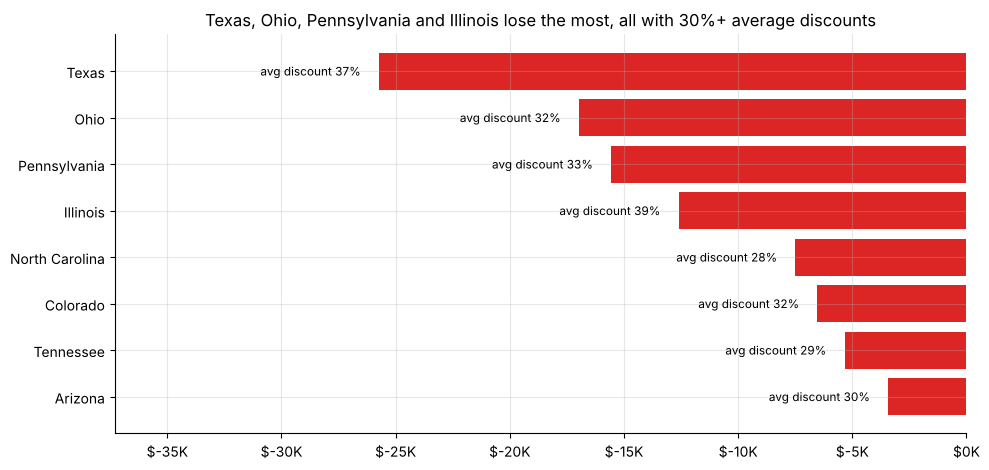

In [14]:
state = orders.groupby("State").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Avg_Discount=("Discount", "mean"))
state["Margin"] = state.Profit / state.Sales
worst = state.sort_values("Profit").head(8)
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(worst.index[::-1], worst.Profit[::-1], color=RED)
for i, (p, d) in enumerate(zip(worst.Profit[::-1], worst.Avg_Discount[::-1])):
    ax.text(p - 800, i, f"avg discount {d:.0%}", va="center", ha="right", fontsize=8.5, color="black")
ax.xaxis.set_major_formatter(usd)
ax.set_xlim(worst.Profit.min() * 1.45, 0)
ax.set_title("Texas, Ohio, Pennsylvania and Illinois lose the most, all with 30%+ average discounts")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/04_loss_making_states.png", dpi=150)

In [15]:
print(f"Loss-making states: {(state.Profit < 0).sum()} of {len(state)}, combined loss ${state.loc[state.Profit < 0, 'Profit'].sum():,.0f}")
print(f"Avg discount in loss-making states: {orders[orders.State.isin(state[state.Profit < 0].index)].Discount.mean():.0%} "
      f"vs {orders[~orders.State.isin(state[state.Profit < 0].index)].Discount.mean():.0%} elsewhere")

Loss-making states: 10 of 49, combined loss $-98,247
Avg discount in loss-making states: 34% vs 4% elsewhere


**Finding:** Central has the lowest margin (7.9%) and the highest average discount (24%). Separately, **West returns 11.7% of orders vs ~3% elsewhere**, a quality or fulfilment issue worth investigating, even though West is the most profitable region. **10 of 49 states lose money** (−$98K combined), led by Texas, Ohio, Pennsylvania and Illinois. Their average discount is **34% vs 4%** in profitable states, which points to a **regional discount policy problem rather than a product problem**.

## 7. Save results

In [16]:
yearly.round(4).to_csv(f"{RESULTS_DIR}/yearly_kpis.csv")
subcat.round(4).to_csv(f"{RESULTS_DIR}/subcategory_profit.csv", index=False)
disc.round(4).to_csv(f"{RESULTS_DIR}/discount_bands.csv")
region.round(4).to_csv(f"{RESULTS_DIR}/region_summary.csv", index=False)
state.sort_values("Profit").round(4).to_csv(f"{RESULTS_DIR}/state_profit.csv")
print("Saved. Next: python scripts/build_excel_workbook.py → results/Superstore_Sales_Analysis.xlsx")

Saved. Next: python scripts/build_excel_workbook.py → results/Superstore_Sales_Analysis.xlsx


## Recommendations
1. **Cap discounts at 20%**, and require manager approval above that. Lines discounted >20% lost $135K.
2. **Fix or reprice Tables and Bookcases.** Raise list prices or stop discounting them; consider dropping the worst Table SKUs.
3. **Run a Central region and Texas/Ohio/Pennsylvania/Illinois discount review** with the regional managers, using the Excel workbook.
4. **Grow the profitable core:** Copiers (37% margin), Accessories, Phones and Paper.
5. **Investigate West's 11.7% return rate** (about 4x other regions), and track it monthly in the workbook's Regions sheet.